### Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

# Collect- and mine data

## Load data

In [1]:
import pandas as pd
from tqdm import tqdm
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
result_dirs = ['../../results/11714894_subsets', '../../results/11824789']
chunks = []
for _, dataset in tqdm(datacol.iterrows(), total=len(datacol)):
    for result_dir in result_dirs:
        respath = os.path.join(result_dir, 'stats', dataset.path + '.csv')
        if os.path.exists(respath):
            chunks.append(pd.read_csv(respath))
statdata = pd.concat(chunks)
del chunks
# statdata.to_csv('./data/statdata.csv', index=False)
print('statdata successfully collected.')

100%|██████████| 1828/1828 [00:16<00:00, 110.46it/s]
statdata successfully collected.


In [2]:
# statdata = pd.read_csv('./data/statdata.csv')
statdata = statdata[statdata['ranking_method'] != 'Stability Selection']
print(statdata.shape)
statdata.head()

(751260, 11)


,cpu_time,feature_rank,ranking_method,replica_no,name,description,recall,precision,fpr,f1,auc
0,3.855204,4.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.333333,0.222222,0.500000,NaN
1,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,NaN
2,3.855204,5.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.250000,0.333333,0.400000,NaN
3,3.855204,3.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.500000,0.111111,0.666667,NaN
4,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,NaN


Load more rebate specific info

In [894]:
rebate = pd.read_csv('./data/rebate-datasets.csv')[[
    'directory', 'heritability', 'edm', 'p_alternate']]
datainfo = datacol.merge(rebate, on='directory')\
              .drop(columns=['replica_no', 'directory', 'path'])\
              .drop_duplicates(ignore_index=True)
datainfo['p_'] = datainfo['p_informative'].str.split(pat=',')
datainfo['p_'] = datainfo['p_'].str.len()
print(datainfo.shape)
datainfo.head()

(76, 11)


,adapter,replicas,name,p,n,description,p_informative,heritability,edm,p_alternate,p_
0,rebate,24,Continuous Features,20,1600,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","18,19","0,4",Easy,None,2
1,rebate,24,20_bit_mutliplexer,20,2000,"20_bit_mutliplexer [p=20,n=2000,p_=20,h=1]","0,1,2,3",1,None,None,4
2,rebate,24,Continuous Endpoints (Threshold),20,1600,"Continuous Endpoints (Threshold) [p=20,n=1600,...","18,19","0,4",Easy,None,2
3,rebate,24,9 Class Balanced Data (2-way Epistasis+ME),20,1600,9 Class Balanced Data (2-way Epistasis+ME) [p=...,"18,19",1,Easy,None,2
4,rebate,24,Total # of Features,1000,1600,"Total # of Features [p=1000,n=1600,p_=2,h=0.4,...","998,999","0,4",Easy,None,2


## Compute metrics
→ PR and ROC Curve

Import `fseval` metrics module

In [831]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [836]:
import sys
sys.path.append('../../')
from fseval.analysis.lib import metrics
metrics.compute_interpolated_metrics

<function fseval.analysis.lib.metrics.compute_interpolated_metrics(replica)>

Compute ROC and PR

In [895]:
tqdm.pandas()

metricdata = statdata\
    .groupby(['description', 'ranking_method', 'replica_no'])\
    .progress_apply(metrics.compute_interpolated_metrics)\
    .reset_index()
aggdata_ = metricdata\
    .groupby(['description', 'ranking_method', 'fpr'])\
    .agg({ 'precision': 'mean', 'tpr': 'mean' })\
    .reset_index()
aggdata_['recall'] = aggdata_['fpr']
aggdata_area = metricdata\
    .groupby(['description', 'ranking_method' ])\
    .agg({ 'auc': 'mean', 'AP': 'mean' })\
    .rename(columns={ 'AP': 'mAP', 'auc': 'AUC' })\
    .reset_index()
aggdata = aggdata_\
    .merge(aggdata_area)\
    .merge(datainfo, on='description', how='left')
print(metricdata.shape)
print(aggdata.shape)
aggdata.head()

(994600, 10)
(41800, 18)


,description,ranking_method,fpr,precision,tpr,recall,AUC,mAP,adapter,replicas,name,p,n,p_informative,heritability,edm,p_alternate,p_
0,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.000000,1.000000,0.000000,0.000000,0.965875,0.855556,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy,None,1
1,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.010101,0.855556,0.791667,0.010101,0.965875,0.855556,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy,None,1
2,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.020202,0.855556,0.791667,0.020202,0.965875,0.855556,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy,None,1
3,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.030303,0.855556,0.791667,0.030303,0.965875,0.855556,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy,None,1
4,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.040404,0.855556,0.791667,0.040404,0.965875,0.855556,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy,None,1


Compute replica counts per recall point for PR curves.

In [310]:
tqdm.pandas()
# Compute Precision/Recall
def attach_pr_info(replica):
    precision, recall, AP = interpolate_pr(replica)
    precision_, recall_, _ = sample_interp_pr(precision, recall)
    return pd.DataFrame({ 'precision': precision_, 'recall': recall_, 'AP': AP })
prdata_ = statdata\
    .groupby(['description', 'ranking_method', 'replica_no'])\
    .progress_apply(attach_pr_info)\
    .reset_index()

# Compute replica count per plateau
def get_counts(data):
    return pd.Series({'counts': data['precision'].count()})
def add_count(data, all_plateaus=None):
    count = data['precision'].count()
    idx = np.argwhere(all_plateaus == count)[0][0]
    plateaus = all_plateaus[idx:]
    return pd.Series({
        'replica count': plateaus,            # vector
        'precision': data['precision'].mean() # scalar
    })
def set_count(group):
    counts = group.groupby('recall').apply(get_counts).reset_index()
    plateaus = np.r_[0, np.where(np.diff(counts['counts'].values))[0] + 1]
    plateaucounts = counts['counts'].values[plateaus]
    assert(~(np.diff(plateaucounts) >= 0).any()) # ensure descending order
    return group.groupby('recall').apply(add_count, all_plateaus=plateaucounts)
prdata = prdata_\
    .groupby(['description', 'ranking_method'])\
    .progress_apply(set_count)\
    .explode('replica count')\
    .astype({'replica count': int })\
    .reset_index()
prdata.shape

100%|██████████| 418/418 [01:47<00:00,  3.89it/s]


(50277, 5)

In [315]:
prdata

,description,ranking_method,recall,replica count,precision
0,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.000000,24,1.000000
1,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.010101,24,0.855556
2,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.020202,24,0.855556
3,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.030303,24,0.855556
4,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.040404,24,0.855556
...,...,...,...,...,...
50272,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,0.959596,24,0.363509
50273,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,0.969697,24,0.363509
50274,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,0.979798,24,0.363509
50275,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,0.989899,24,0.363509


# 3-way Epistasis example

In [432]:
exname = '3-way Epistasis (GAMETES)'
exdata = aggdata[aggdata['name'] == exname]
exdata['description'].values[0]

'3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=0.4,edm=Easy]'

Raw ranking data in table format

In [7]:
# informative features for this dataset are: `p_informative=[17, 18, 19]`
exdata_replica1 = pd.read_csv('../../results/11714894_subsets/ranking/data/rebate/GAMETES_2.2_dev_peter_epi_order_Datasets_Loc_3_Qnt_2_Pop_100000/a_20/s_1600/her_0.2__maf_0.2/a_20s_1600her_0.2__maf_0.2_EDM-2/a_20s_1600her_0.2__maf_0.2_EDM-2_01.txt.gz.csv')
exdata_replica1_ = exdata_replica1[exdata_replica1['ranking_method'] == 'ExtraTrees']\
    .sort_values('feature_rank')
exdata_replica1_['informative'] = exdata_replica1_['feature_index'].isin([17, 18, 19])
exdata_replica1_['informative'] = exdata_replica1_['informative'].map(lambda bool: 'Y' if bool else 'N')
exdata_replica1_['feature_rank'] = exdata_replica1_['feature_rank'].astype(int)
exdata_replica1_['feature_index'] = exdata_replica1_['feature_index'].astype(int)
exdata_replica1_t = exdata_replica1_[['feature_rank', 'feature_index', 'informative']].transpose()
exdata_replica1_t # can be copied into https://www.tablesgenerator.com/latex_tables

,64,61,60,51,62,59,53,55,58,63,54,56,57,52
feature_rank,1,2,3,4,5,6,7,8,9,10,11,12,13,14
feature_index,19,16,15,2,17,14,6,8,12,18,7,10,11,3
informative,Y,N,N,N,Y,N,N,N,N,Y,N,N,N,N


## Plots for just ExtraTrees

In [89]:
et_rm = 'ExtraTrees'
et = statdata[(statdata['name'] == exname) &\
              (statdata['ranking_method'] == et_rm)]
et = et.sort_values('feature_rank')
et.shape

(285, 11)

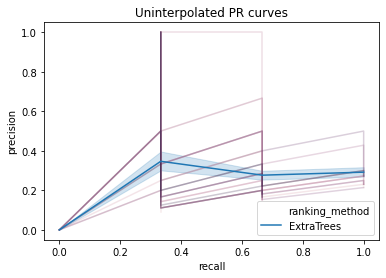

In [90]:
g = sns.lineplot(data=et, x='recall', y='precision', hue='replica_no',\
                 estimator=None, units='replica_no',
                 legend=False, sort=False, alpha=0.25)
g = sns.lineplot(data=et, x='recall', y='precision', hue='ranking_method')
plt.title('Uninterpolated PR curves')
plt.show()

In [91]:
mAP = []
mP = [] # mean precisions
mR = [] 
for _, replica in et.groupby('replica_no'):
    precision, recall, AP = interpolate_pr(replica)
    precision_, recall_, _ = sample_interp_pr(precision, recall)
    mAP.append(AP)
    mP.append(precision_)
    mR.append(recall_)
m_AP = np.mean(mAP)
m_P = np.nanmean(mP, axis=0)
m_R = np.mean(mR, axis=0)

counts = np.count_nonzero(~np.isnan(mP), axis=0)
norm_counts = counts / counts.max() / 5
diff_counts = np.where(np.r_[0, np.diff(m_P)])[0]
labels_recall = np.array(m_R)[[diff_counts]]
labels_count = counts[diff_counts]
labels_y = m_P[diff_counts + 1]
all_counts = [norm_counts for _ in range(len(mP))]

data = pd.DataFrame({
    'precision': pd.Series(mP).explode().astype(float),
    'recall': pd.Series(mR).explode().astype(float),
    'replicas': pd.Series(all_counts).explode().astype(float),
    'ranking_method': et_rm
})
data['replica'] = data.index
# sns.lineplot(x=m_R, y=m_P)
# plt.ylim(0, 1)
# np.trapz(m_P, m_R)
list(zip(labels_recall, labels_y, labels_count))

[(0.010101010101010105, 0.7215277777777778, 24),
 (0.3333333333333332, 0.381711525189786, 23),
 (0.6666666666666664, 0.29931734931734927, 12)]

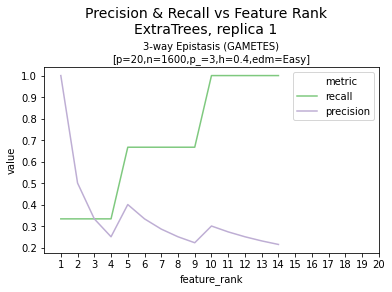

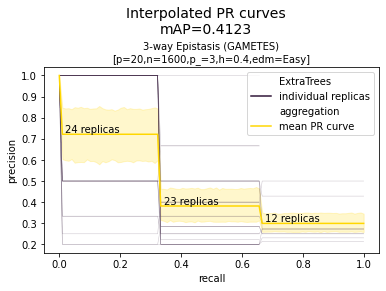

In [92]:
##### Uninterpolated PR curve replica 1
repl1 = et[et['replica_no'] == 1]
repl1_ = repl1.melt(id_vars=['feature_rank'], value_vars=['recall', 'precision'],\
                   var_name='metric')
plt.xticks(np.arange(1, 20+1, 1.0))
plt.xlim(right=20)
sns.lineplot(data=repl1_,
             x='feature_rank',
             y='value',
             hue='metric',
             palette="Accent")
plt.suptitle('Precision & Recall vs Feature Rank\n{}, replica 1'\
    .format(et_rm), size=14)
plt.subplots_adjust(top=.77)
plt.title("3-way Epistasis (GAMETES)\n[p=20,n=1600,p_=3,h=0.4,edm=Easy]", size=10)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_repl1pr.svg')
plt.show()

##### Interpolated PR curves (mAP)
data1 = data.copy()
data1[et_rm] = 'individual replicas'
sns.lineplot(data=data1, x='recall', y='precision', estimator=None, units='replica',
    lw=0.5, alpha=0.25, hue=et_rm, palette='twilight')
data2 = data.copy()
data2['aggregation'] = 'mean PR curve'
sns.lineplot(data=data2, x='recall', y='precision', hue='aggregation', palette='prism')
for point in zip(labels_recall, labels_count, labels_y):
    recall, count, y = point
    plt.text(recall + 0.01, y + 0.01, '{} replicas'.format(count))
plt.suptitle('Interpolated PR curves\nmAP={:.4f}'.format(m_AP), size=14)
plt.subplots_adjust(top=.77)
plt.title("3-way Epistasis (GAMETES)\n[p=20,n=1600,p_=3,h=0.4,edm=Easy]", size=10)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_etpr.svg')
plt.show()

# Dataset themes
_en masse_

Attach legend abbreviations

In [897]:
ranking_methods_short = {
    'ExtraTrees': 'ET',
    'FeatBoost': 'FB',
    'FeatBoost Deep': 'FB Deep',
    'FeatBoost w/1-NN': 'FB 1-NN',
    'MultiSURF': 'M-SURF',
    'RFE w/XGBoost': 'RFE'
}
aggdata['method'] = aggdata['ranking_method']\
    .map(ranking_methods_short.get)
aggdata['plttitle'] = aggdata['description']\
    .map(lambda d: d.replace(' [p=', '\n[p='))
aggdata.method.unique()

array(['ET', 'FB', 'FB Deep', 'FB 1-NN', 'M-SURF', 'RFE'], dtype=object)

## 3-way Pure Epistasis

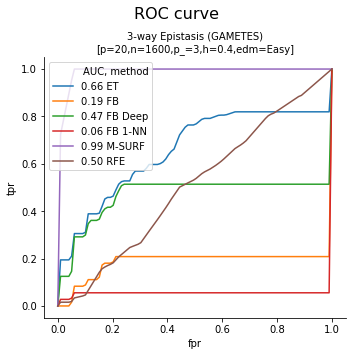

In [889]:
g = sns.relplot(data=aggdata[
        aggdata['name'] == '3-way Epistasis (GAMETES)'
    ],
    x='fpr', y='tpr', hue='ranking_method',
    kind='line', col='plttitle',
    facet_kws={'legend_out': False})
metrics.add_metric_to_legend(g, 'AUC', 'method', hue_var='ranking_method')
g.set_titles("{col_name}")
g.fig.suptitle("ROC curve", size=16)
g.fig.subplots_adjust(top=.84)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_roc.svg')
plt.show()

In [879]:
ranking_methods_short = {
    'ExtraTrees': 'ET',
    'FeatBoost': 'FB',
    'FeatBoost Deep': 'FB Deep',
    'FeatBoost w/1-NN': 'FB 1-NN',
    'MultiSURF': 'M-SURF',
    'RFE w/XGBoost': 'RFE'
}
prdata['method'] = prdata['ranking_method']\
    .map(ranking_methods_short.get)
prdata['plttitle'] = prdata['description']\
    .map(lambda d: d.replace(' [p=', '\n[p='))
superdata = prdata[prdata['description'] == '3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=0.4,edm=Easy]']
tomerge = aggdata[aggdata['description'] == '3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=0.4,edm=Easy]'][['description', 'ranking_method', 'mAP']]

# for a,b in tomerge.groupby('ranking_method'):
#     print(a)
#     superdata[superdata['ranking_method']==a]['mAP']=b['mAP'].values[0]
tomerge_ = tomerge.groupby(['description', 'ranking_method']).agg('mean').reset_index()
superdata = superdata.merge(tomerge_)

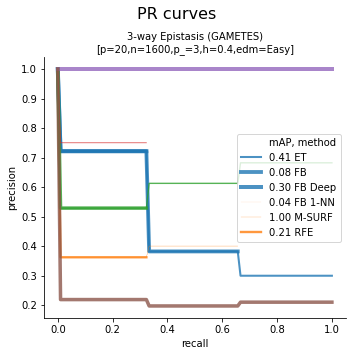

In [890]:
g = sns.relplot(data=superdata,
    x='recall', y='precision', hue='ranking_method',
    kind='line', col='plttitle', 
    size='replica count', sizes=(.10, 4.0),
    legend=False,
    alpha=0.80, facet_kws={'legend_out': False}
    )
metrics.add_metric_to_legend(g, 'mAP', 'method', hue_var='ranking_method')
g.set_titles("{col_name}")
g.fig.suptitle("PR curves", size=16)
g.fig.subplots_adjust(top=.84)
# plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_pr.png')
# plt.show()

## 1 Main Effect

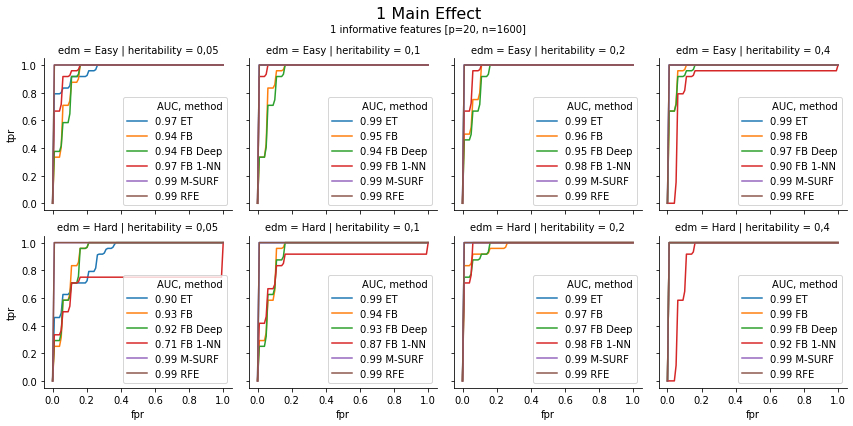

In [992]:
themename = '1 Main Effect'
themedata = aggdata[
        aggdata['name'] == themename
    ]

row, col = 'edm', 'heritability'
g = sns.FacetGrid(themedata, col=col, row=row, hue="ranking_method")
g.map(sns.lineplot, "fpr", "tpr")
metrics.add_metric_to_legend(g, 'AUC', 'method')
plt.figtext(.5, .92, '{} informative features [p={}, n={}]'.format(
        themedata.p_.values[0], themedata.p.values[0], themedata.n.values[0]
    ), fontsize=10, ha='center')
g.fig.suptitle('{}'.format(themename), size=16)
g.fig.subplots_adjust(top=.86)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/1_main_effect.svg')
plt.show()

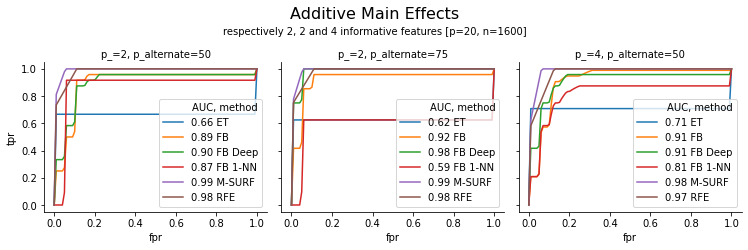

In [1001]:
themename = 'Additive Main Effects'
themedata = aggdata[
        aggdata['name'].str.contains('Additive Main Effects')
    ]
themedata['pinf_and_palt'] = themedata['p_'].combine(themedata['p_alternate'],\
    lambda p_, p_alt: 'p_={}, p_alternate={}'.format(p_, p_alt))

g = sns.FacetGrid(themedata, col='pinf_and_palt',hue="ranking_method",
    size=3.5, aspect=1)
g.map(sns.lineplot, "fpr", "tpr")
metrics.add_metric_to_legend(g, 'AUC', 'method')
plt.figtext(.5, .87, 'respectively 2, 2 and 4 informative features [p={}, n={}]'.format(
        themedata.p.values[0], themedata.n.values[0]
    ), fontsize=10, ha='center')
g.fig.suptitle('{}'.format(themename), size=16)
g.fig.subplots_adjust(top=.76)
g.set_titles('{col_name}')
plt.savefig('/Users/dunnkers/git/research-internship-report/img/additive_main_effects.svg')
plt.show()

## 2-way Epistasis

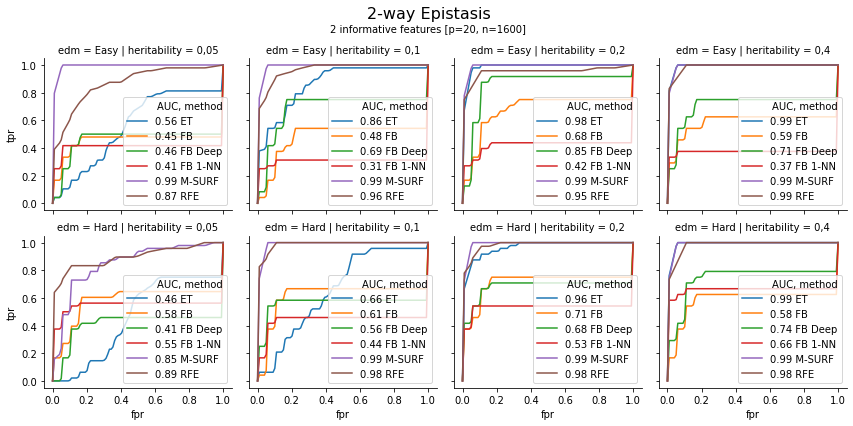

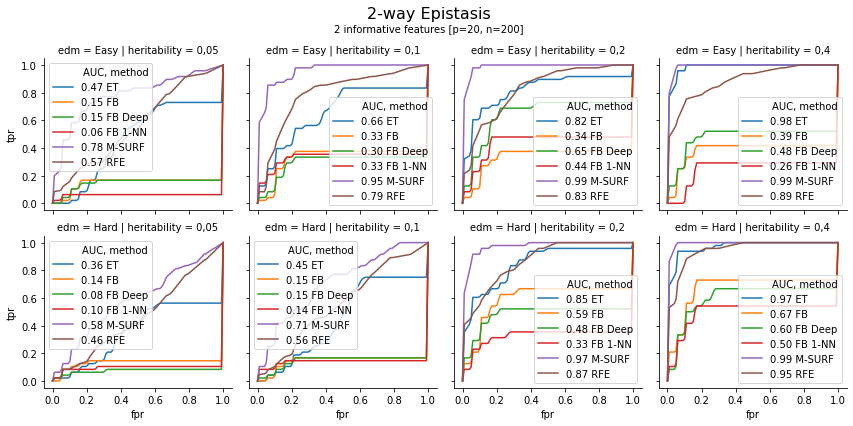

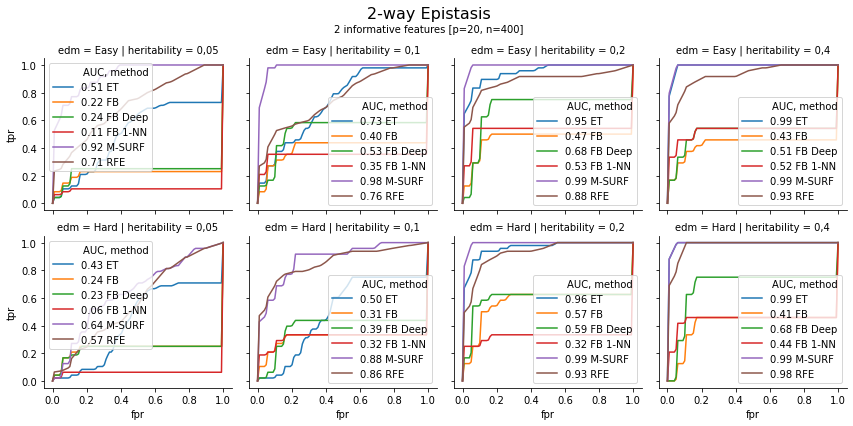

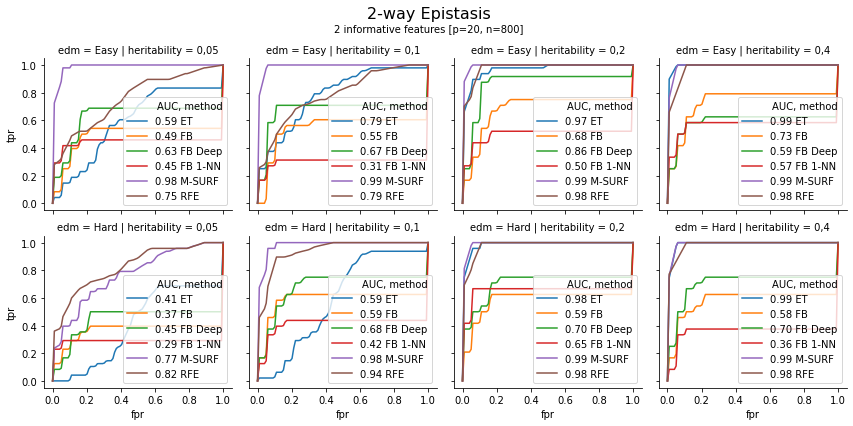

In [936]:
themename = '2-way Epistasis'
themedata_ = aggdata[
        aggdata['name'] == themename
    ]
for n, themedata in themedata_.groupby('n'):
    row, col = 'edm', 'heritability'
    g = sns.FacetGrid(themedata, col=col, row=row, hue="ranking_method")
    g.map(sns.lineplot, "fpr", "tpr")
    metrics.add_metric_to_legend(g, 'AUC', 'method')
    plt.figtext(.5, .92, '{} informative features [p={}, n={}]'.format(
            themedata.p_.values[0], themedata.p.values[0], n
        ), fontsize=10, ha='center')
    g.fig.suptitle('{}'.format(themename), size=16)
    g.fig.subplots_adjust(top=.86)
    plt.savefig('/Users/dunnkers/git/research-internship-report/img/2way_n={}.svg'.format(n))
    plt.show()

## Genetic Heterogeneity

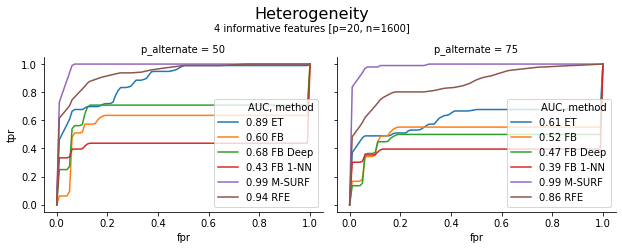

In [938]:
themename = 'Heterogeneity'
themedata = aggdata[
        aggdata['name'] == themename
    ]

g = sns.FacetGrid(themedata, col='p_alternate', hue="ranking_method",
     size=3.5, aspect=1.25)
g.map(sns.lineplot, "fpr", "tpr")
metrics.add_metric_to_legend(g, 'AUC', 'method')
plt.figtext(.5, .88, '{} informative features [p={}, n={}]'.format(
        themedata.p_.values[0], themedata.p.values[0], themedata.n.values[0]
    ), fontsize=10, ha='center')
g.fig.suptitle('{}'.format(themename), size=16)
g.fig.subplots_adjust(top=.78)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/genetic_heterogeneity.svg')
plt.show()

## XOR benchmarks

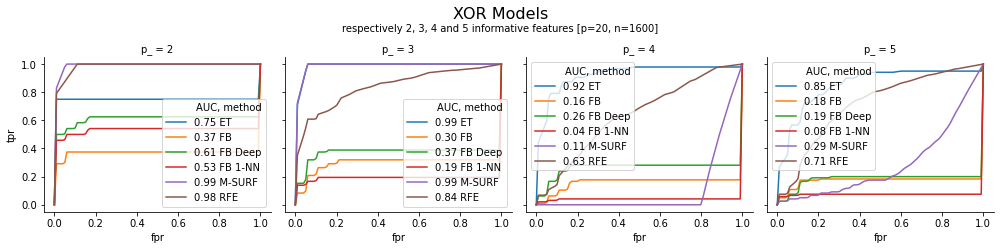

In [928]:
themename = 'XOR Models'
themedata = aggdata[
        aggdata['name'] == themename
    ]

g = sns.FacetGrid(themedata, col='p_', hue="ranking_method",
     size=3.5, aspect=1)
g.map(sns.lineplot, "fpr", "tpr")
metrics.add_metric_to_legend(g, 'AUC', 'method')
plt.figtext(.5, .88, 'respectively 2, 3, 4 and 5 informative features [p={}, n={}]'.format(
        themedata.p.values[0], themedata.n.values[0]
    ), fontsize=10, ha='center')
g.fig.suptitle('{}'.format(themename), size=16)
g.fig.subplots_adjust(top=.78)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/xor_benchmarks.svg')
plt.show()

## Total # of Features

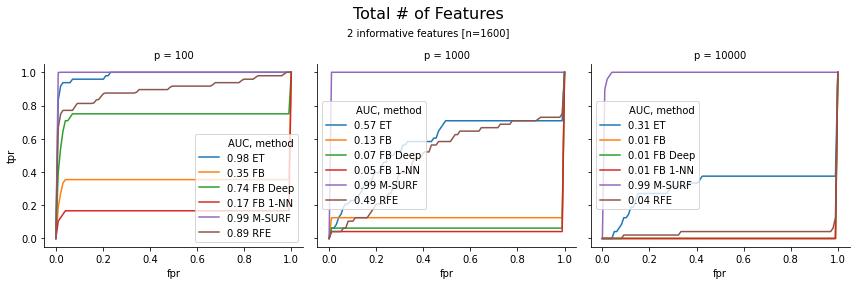

In [930]:
themename = 'Total # of Features'
themedata = aggdata[
        aggdata['name'] == themename
    ]

g = sns.FacetGrid(themedata, col='p', hue="ranking_method",
     size=4, aspect=1)
g.map(sns.lineplot, "fpr", "tpr")
metrics.add_metric_to_legend(g, 'AUC', 'method')
plt.figtext(.5, .88, '{} informative features [n={}]'.format(
        themedata.p_.values[0], themedata.n.values[0]
    ), fontsize=10, ha='center')
g.fig.suptitle('{}'.format(themename), size=16)
g.fig.subplots_adjust(top=.78)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/total_features.svg')
plt.show()

## Multiplexer benchmarks

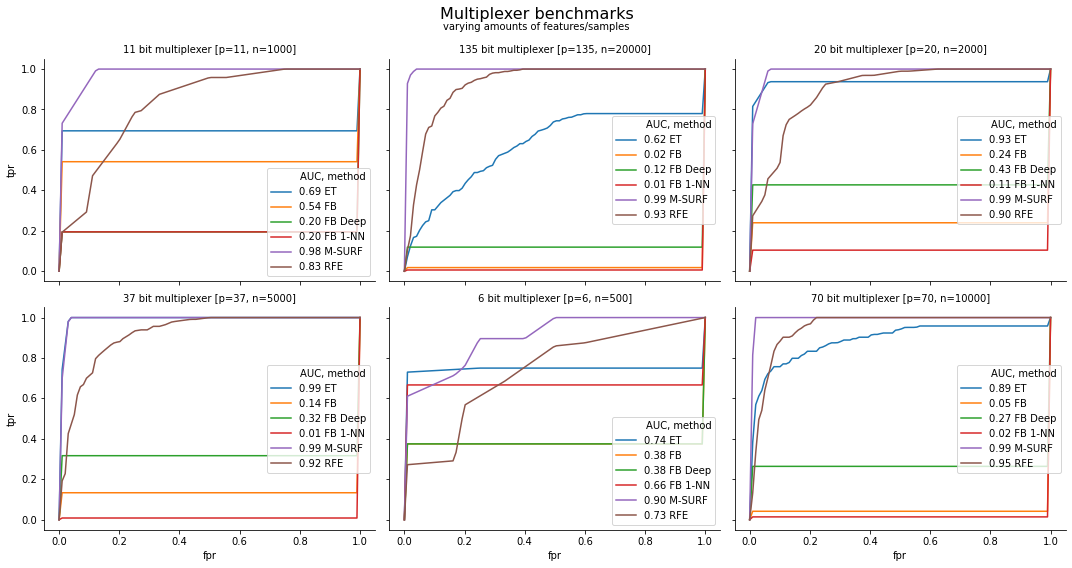

In [989]:
themename = 'Multiplexer benchmarks'
themedata = aggdata[
        aggdata['name'].str.contains('mutliplexer')
    ]
themedata['p_and_n'] = themedata['p'].combine(themedata['n'],\
    lambda p, n: '{} bit multiplexer [p={}, n={}]'.format(p, p, n))
g = sns.FacetGrid(themedata, col='p_and_n', hue="ranking_method",
     size=4, aspect=1.25, col_wrap=3)
g.map(sns.lineplot, "fpr", "tpr")
add_metric_to_legend(g, 'AUC', 'method')
plt.figtext(.5, .94, 'varying amounts of features/samples',
    fontsize=10, ha='center')
g.fig.suptitle('{}'.format(themename), size=16)
g.fig.subplots_adjust(top=.89)
g.set_titles('{col_name}')
plt.savefig('/Users/dunnkers/git/research-internship-report/img/multiplexer_benchmarks.svg')
plt.show()

## Continuous Endpoints

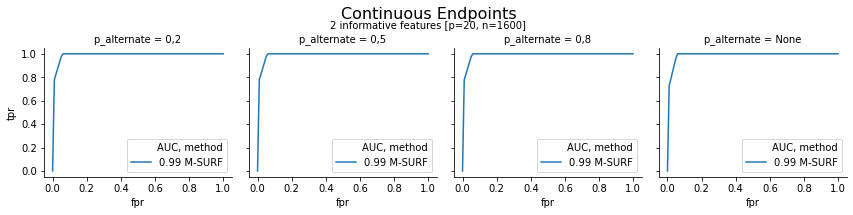

In [1007]:
themename = 'Continuous Endpoints'
themedata = aggdata[
        aggdata['name'].str.contains('Continuous Endpoints')
    ]
g = sns.FacetGrid(themedata, col='p_alternate', hue="ranking_method",
    ) #  size=4, aspect=1.25, col_wrap=3)
g.map(sns.lineplot, "fpr", "tpr")
add_metric_to_legend(g, 'AUC', 'method')
plt.figtext(.5, .88, '{} informative features [p={}, n={}]'.format(
        themedata.p_.values[0], themedata.p.values[0], themedata.n.values[0]
    ), fontsize=10, ha='center')
g.fig.suptitle('{}'.format(themename), size=16)
g.fig.subplots_adjust(top=.79)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/continuous_endpoints.svg')
plt.show()

## Data Types

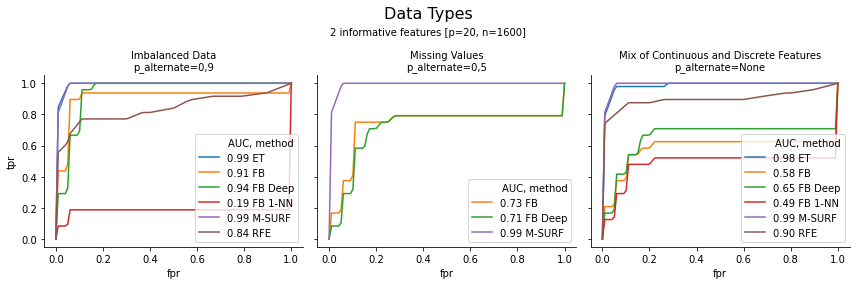

In [1029]:
themename = 'Data Types'
themedata = aggdata[
        (aggdata['name'] == 'Missing Values') |
        (aggdata['name'] == 'Imbalanced Data') |
        (aggdata['name'] == 'Mix of Continuous and Discrete Features')
    ]
themedata = themedata[
        (aggdata['p_alternate'] == '0,9') |
        (aggdata['p_alternate'] == '0,5') | 
        (aggdata['p_alternate'] == 'None')
]
themedata['coltitle'] = themedata['p_alternate'].combine(themedata['name'],
    lambda p_alt, name: '{}\np_alternate={}'.format(name, p_alt))
g = sns.FacetGrid(themedata, col='coltitle', hue="ranking_method",
    size=4) #  aspect=1.25, col_wrap=3)
g.map(sns.lineplot, "fpr", "tpr")
add_metric_to_legend(g, 'AUC', 'method')
plt.figtext(.5, .88, '{} informative features [p={}, n={}]'.format(
        themedata.p_.values[0], themedata.p.values[0], themedata.n.values[0]
    ), fontsize=10, ha='center')
g.fig.suptitle('{}'.format(themename), size=16)
g.fig.subplots_adjust(top=.74)
g.set_titles('{col_name}')
plt.savefig('/Users/dunnkers/git/research-internship-report/img/data_types.svg')
plt.show()

# All datasets

mAP scores

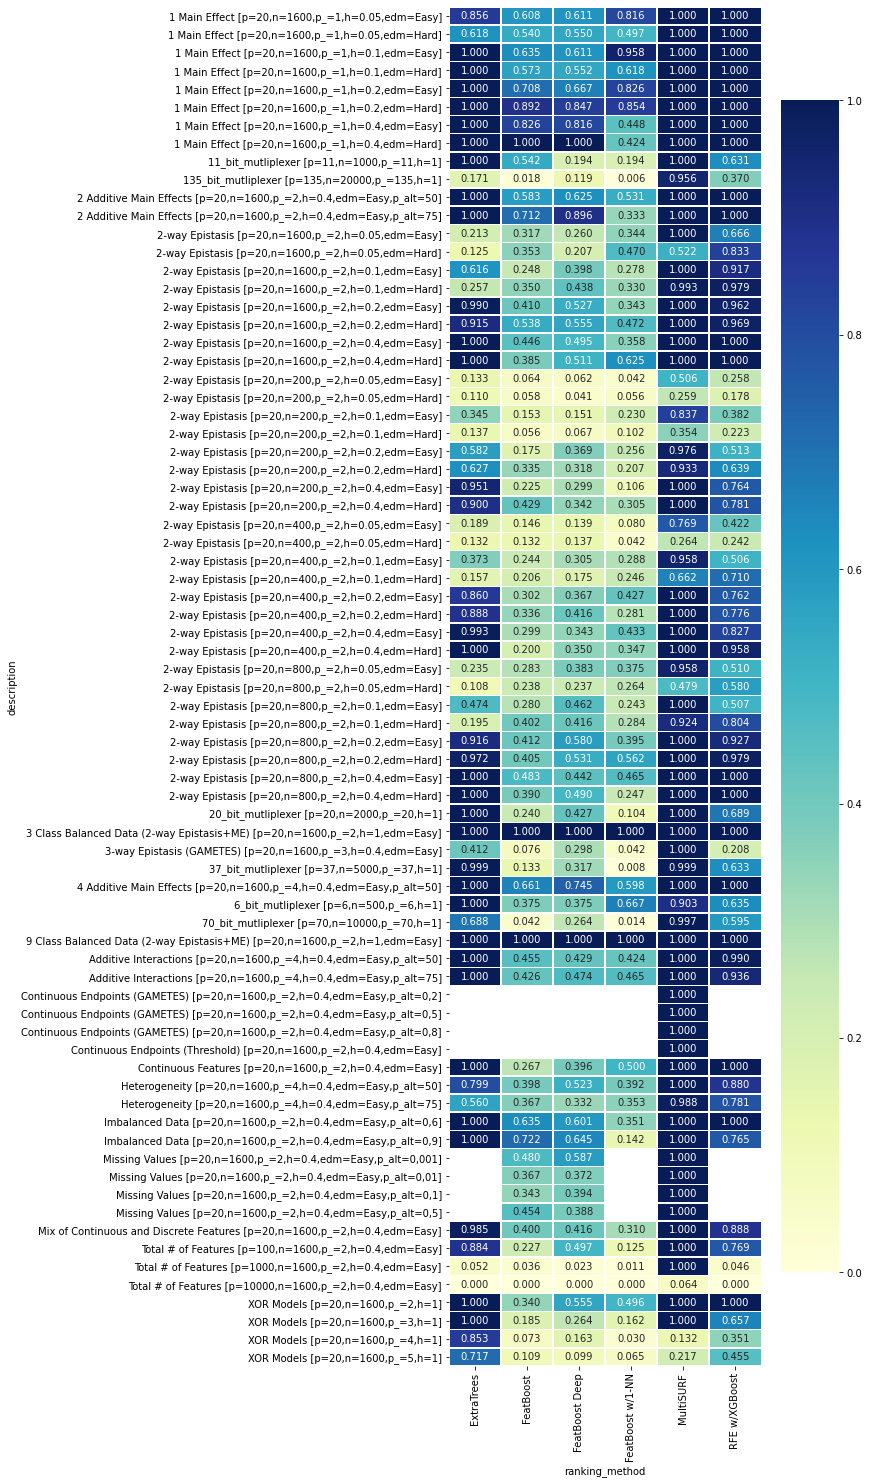

In [141]:
rectangular = pd.pivot_table(interpdata,\
    values='mAP',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".3f", linewidths=.5,\
    cmap="YlGnBu", yticklabels=True, ax=ax)

AUC scores

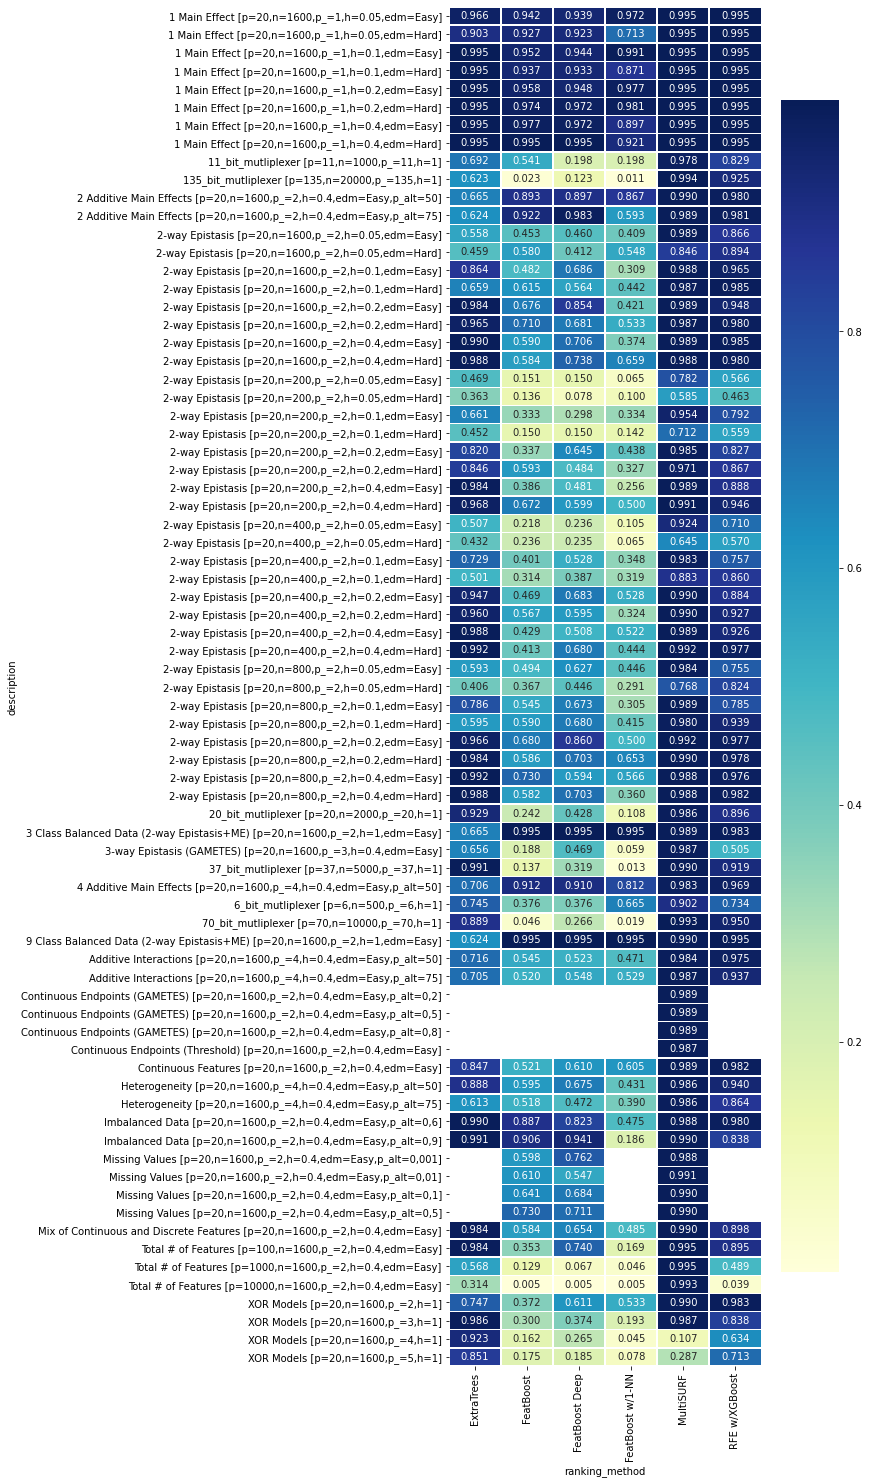

In [103]:
roc_auc_pivot = pd.pivot_table(interpdata,\
    values='roc_auc',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(roc_auc_pivot,\
    annot=True, fmt=".3f", linewidths=.5,\
    cmap="YlGnBu", yticklabels=True, ax=ax)

CPU timings

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

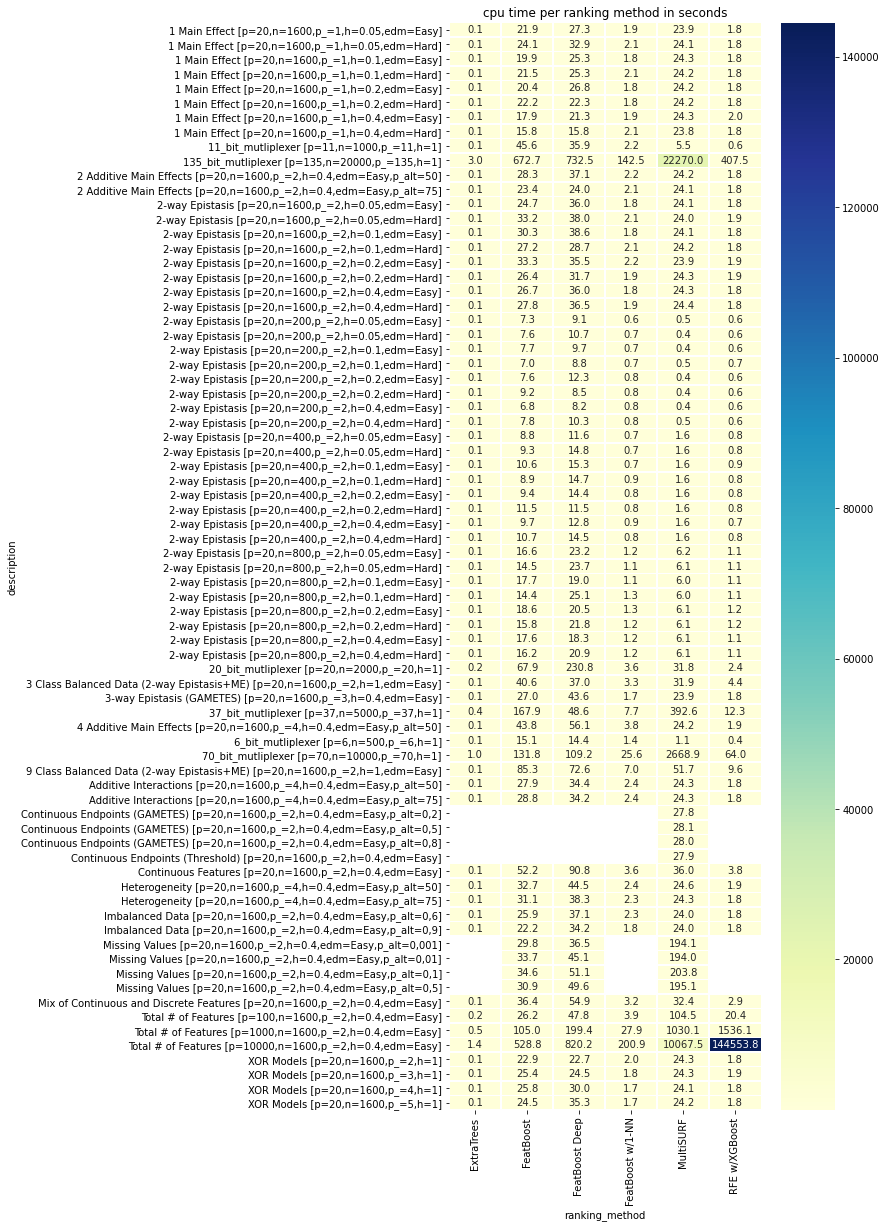

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
pivot = pd.pivot_table(statdata,\
    values='cpu_time', index=['description'], columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 20))
ax = sns.heatmap(pivot, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('cpu time per ranking method in seconds')

# Statistical integrity testing

In [311]:
avgdata = interpdata.groupby(['description', 'ranking_method']).agg('mean').reset_index()
avgdata.shape

(418, 8)

### ROC-AUC

In [164]:
from scipy.stats import friedmanchisquare
pivot_rocauc = pd.pivot_table(avgdata, values='roc_auc',\
    index=['description'], columns=['ranking_method'])
res = friedmanchisquare(*pivot_rocauc.values.transpose())
print('significant' if res.pvalue < 0.05 else 'insignificant')
res

significant


FriedmanchisquareResult(statistic=201.4500390320062, pvalue=1.390596061390306e-41)

In [160]:
melted_rocauc = avgdata.melt(id_vars=['description', 'ranking_method'], value_vars=['roc_auc'])
melted_rocauc.head()

,description,ranking_method,variable,value
0,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,roc_auc,0.965875
1,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",FeatBoost,roc_auc,0.941528
2,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",FeatBoost Deep,roc_auc,0.939343
3,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",FeatBoost w/1-NN,roc_auc,0.972448
4,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",MultiSURF,roc_auc,0.994949


In [158]:
import scikit_posthocs  as sp
pc = sp.posthoc_nemenyi_friedman(melted_rocauc, y_col='value', block_col='description',
    group_col='ranking_method', melted=True)
pc

,ExtraTrees,FeatBoost,FeatBoost Deep,FeatBoost w/1-NN,MultiSURF,RFE w/XGBoost
ExtraTrees,-1.00000,0.001000,0.001000,0.001000,0.031570,0.900000
FeatBoost,0.00100,-1.000000,0.883234,0.161496,0.001000,0.001000
FeatBoost Deep,0.00100,0.883234,-1.000000,0.006938,0.001000,0.001000
FeatBoost w/1-NN,0.00100,0.161496,0.006938,-1.000000,0.001000,0.001000
MultiSURF,0.03157,0.001000,0.001000,0.001000,-1.000000,0.353392
RFE w/XGBoost,0.90000,0.001000,0.001000,0.001000,0.353392,-1.000000


(<matplotlib.axes._subplots.AxesSubplot at 0x12bfc6978>,
 <matplotlib.colorbar.ColorbarBase at 0x12a9e6c88>)

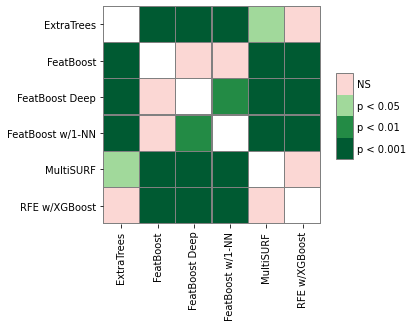

In [159]:
heatmap_args = {'linewidths': 0.25, 'linecolor': '0.5', 'clip_on': False, 'square': True, 'cbar_ax_bbox': [0.80, 0.35, 0.04, 0.3]}

### mAP

significant


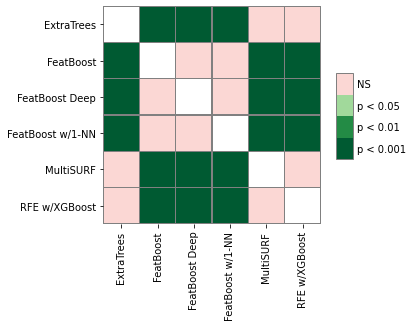

In [187]:
from scipy.stats import friedmanchisquare
import scikit_posthocs  as sp
pivot_rocauc = pd.pivot_table(avgdata, values='mAP',\
    index=['description'], columns=['ranking_method'])
res = friedmanchisquare(*pivot_rocauc.values.transpose())
if res.pvalue < 0.05:
    print('significant')
    melted_mAP = avgdata.melt(id_vars=['description', 'ranking_method'], value_vars=['mAP'])
    pc = sp.posthoc_nemenyi_friedman(melted_rocauc, y_col='value', block_col='description',
        group_col='ranking_method', melted=True)
    sp.sign_plot(pc, **heatmap_args)
    # plt.title('mAP significance levels')

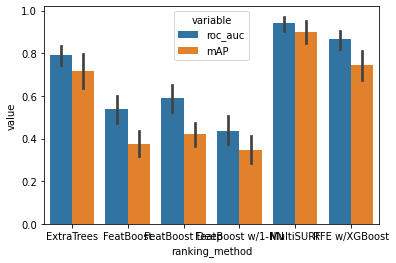

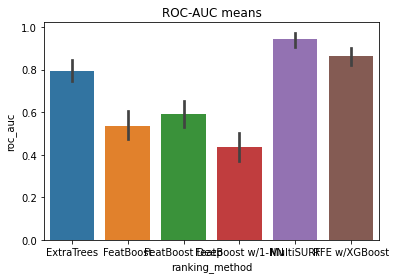

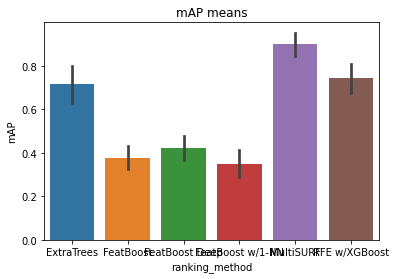

In [190]:
summary_ = avgdata.melt(id_vars=['ranking_method'], value_vars=['roc_auc', 'mAP'])
sns.barplot(data=summary_, x='ranking_method', y='value', hue='variable')
plt.show()
sns.barplot(data=avgdata, x='ranking_method', y='roc_auc')
plt.title('ROC-AUC means')
plt.show()
sns.barplot(data=avgdata, x='ranking_method', y='mAP')
plt.title('mAP means')
plt.show()